<a href="https://colab.research.google.com/github/fdac25/MP2/blob/main/Vis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import os
yournetid = 'mmariaru'

projects = [
    'calamari-ocr_calamari',
    'pdclab_peregrine',
    'juliaopt_pajarito.jl',
    'mic-dkfz_batchgenerators',
    'romerogroup_pyprocar',
    'jean-romain_lidr',
    'google-research_football',
    'drostlab_philentropy',
    'contextlab_hypertools',
    'lima1_purecn',
]

In [3]:
df = pd.read_csv("mmariaru_project_summary.csv", sep=";")
df.columns = ['project','commit','author','time','message']
df['Month'] = pd.to_datetime(df['time'], unit='s').dt.strftime('%Y-%m')
df.head()

,project,commit,author,time,message,Month
0,calamari-ocr_calamari,0123fe4d1694365ffacff2d0ae66b913acf5e0bb,Christoph Wick <wick.chr.info@gmail.com>,1536677973,added support for abbyy.xml files as input (ne...,2018-09
1,calamari-ocr_calamari,017766a18c260883f87747dfd3ee061dd36179d7,Christoph Wick <wick.chr.info@gmail.com>,1571820729,Ignoring NaN as CER in early stopping\n,2019-10
2,calamari-ocr_calamari,02d46bf03a7371beae462e41f6f5b6d42151566c,Christoph Wick <wick.chr.info@gmail.com>,1571995296,Added training callback to allow external prog...,2019-10
3,calamari-ocr_calamari,02e8494dee305f250f475cd674e412fdf0e31ec3,Andreas Büttner <andbue@gmail.com>,1611766090,dtype set\n,2021-01
4,calamari-ocr_calamari,0390f2ab8568a7d817595e86510d529d06fa141a,C. Wick <wick.chr@gmail.com>,1613855306,refactoring\n,2021-02


In [4]:
prj = projects[0]
df1 = df[df['project']==prj]
df2 = df1.groupby('Month').size().reset_index(name='Commits')
monthly_counts = df2
monthly_counts['time'] = pd.to_datetime(monthly_counts['Month'])
full_date_range = pd.DataFrame({'time': pd.date_range(start=monthly_counts['time'].min(), end=monthly_counts['time'].max(), freq='MS')})
monthly_counts = pd.merge(full_date_range, monthly_counts, on='time', how='left').fillna(0)
monthly_counts['Month'] = monthly_counts['time'].dt.strftime('%Y-%m')

## Monthly time series and plots for all 10 projects

In [5]:
monthly_series = {}

for prj in projects:
    sub = df[df['project'] == prj]
    if sub.empty:
        print('No rows for', prj)
        continue
    months = pd.period_range(sub['Month'].min(), sub['Month'].max(), freq='M').astype(str)
    counts = sub.groupby('Month').size().reindex(months, fill_value=0)   # zero-fill empty months
    ts = pd.DataFrame({'Month': months, '#Commits': counts.values})
    ts.to_csv(f'{yournetid}_commits_timeseries_{prj}.csv', sep=';', index=False)
    monthly_series[prj] = ts

print('Wrote', len(monthly_series), 'timeseries csv files')
monthly_series[projects[0]].head()

Wrote 10 timeseries csv files


,Month,#Commits
0,2018-03,4
1,2018-04,25
2,2018-05,29
3,2018-06,19
4,2018-07,20


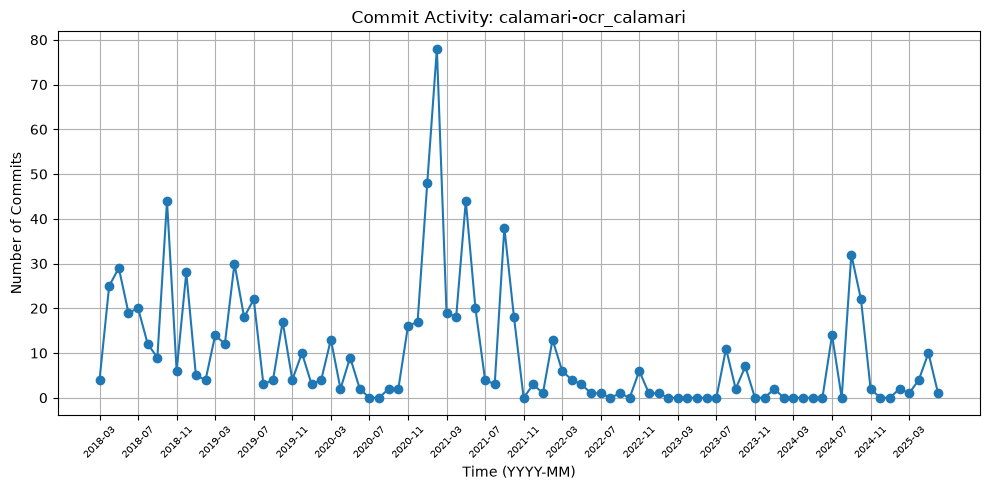

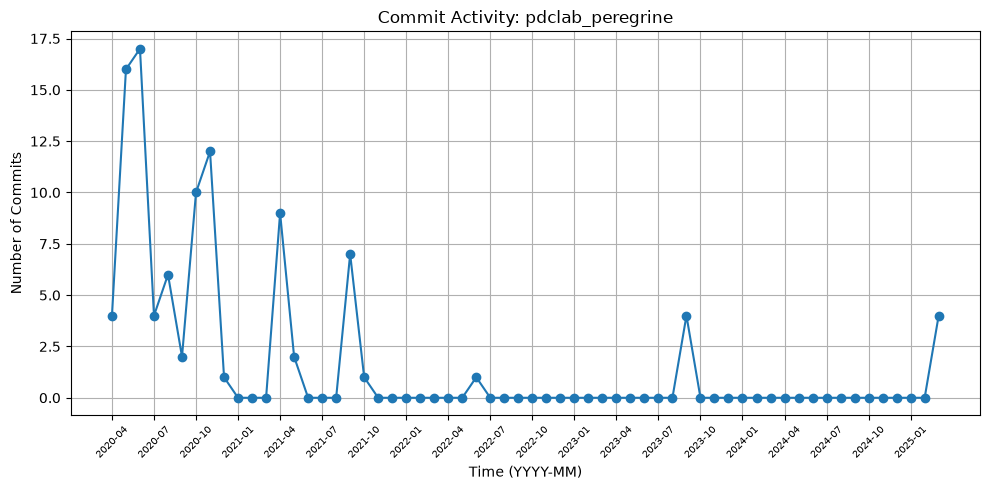

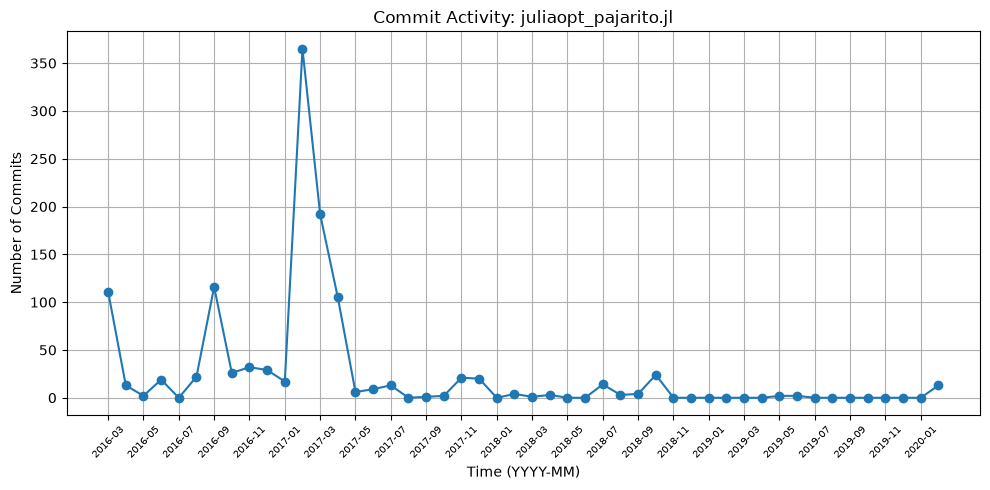

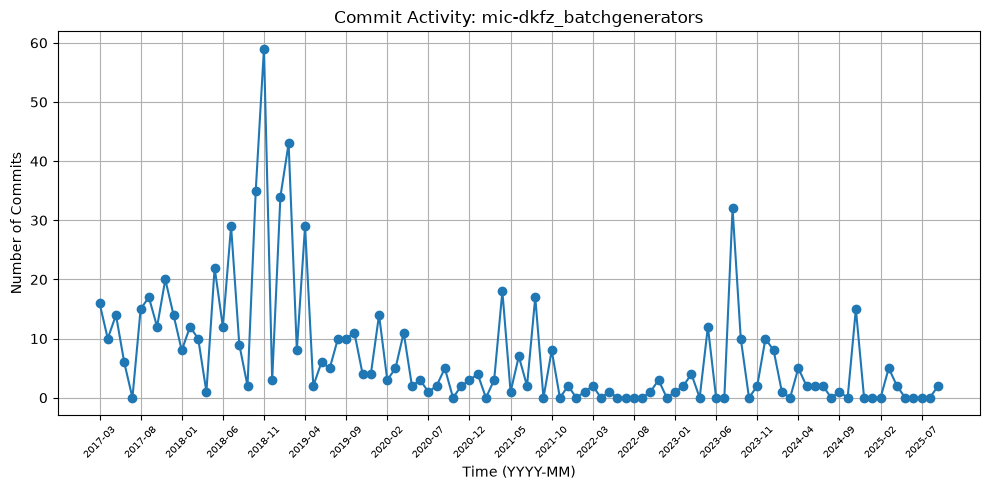

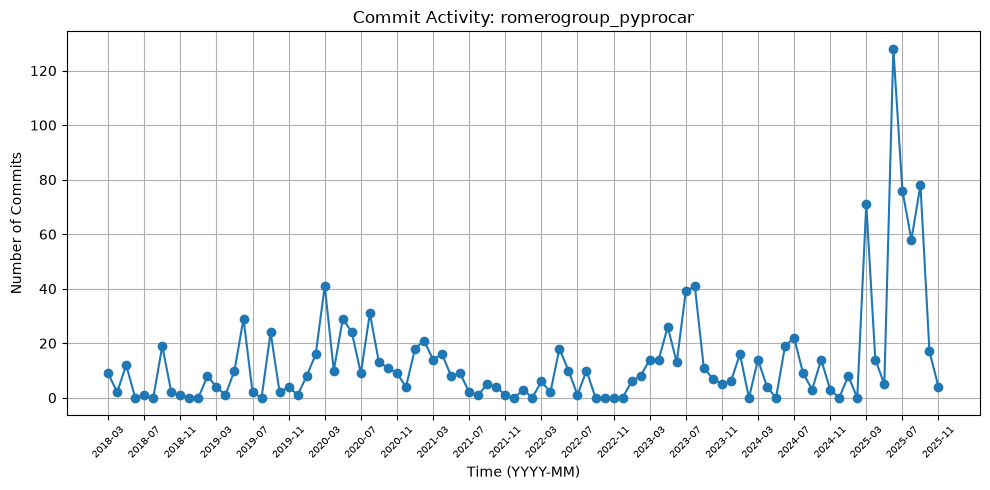

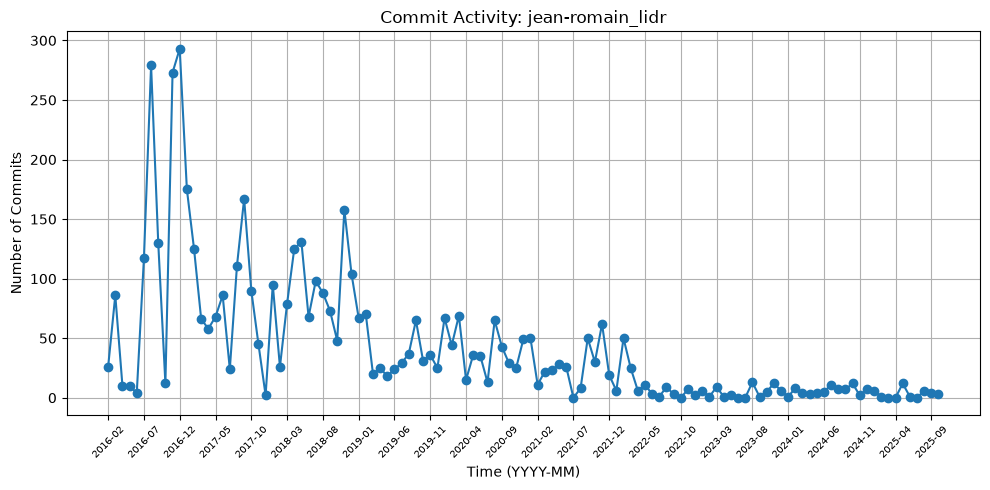

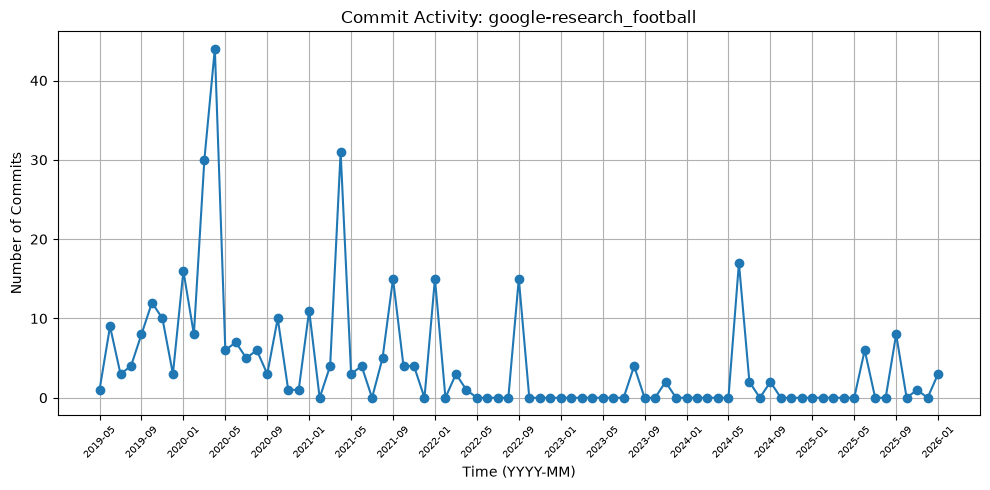

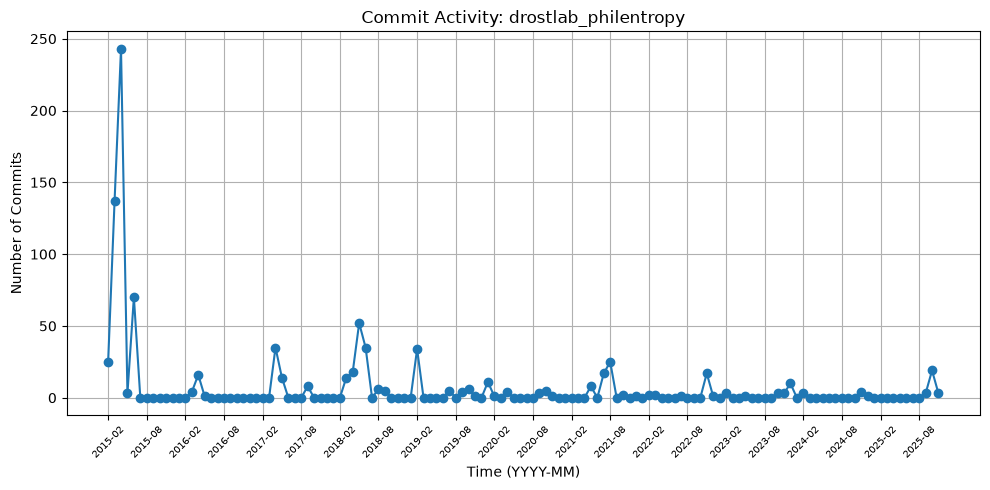

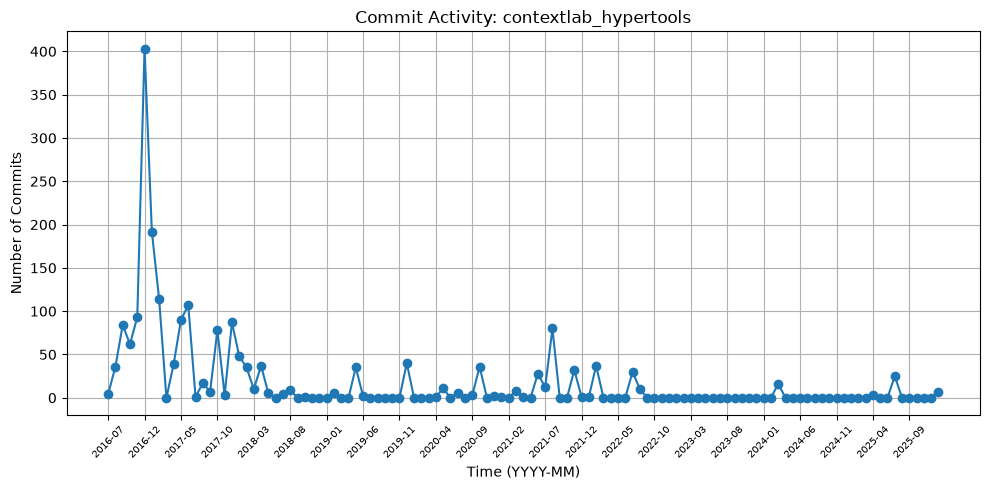

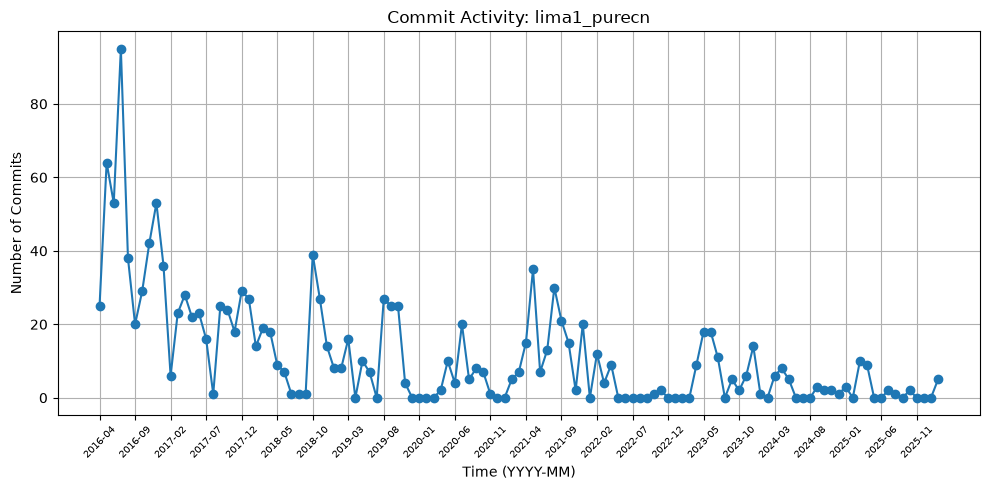

In [6]:
for prj in projects:
    path = f'{yournetid}_commits_timeseries_{prj}.csv'
    if not os.path.exists(path):
        continue
    ts = pd.read_csv(path, sep=';')

    plt.figure(figsize=(10, 5))
    plt.plot(ts['Month'], ts['#Commits'], marker='o', linestyle='-')
    plt.xlabel('Time (YYYY-MM)')
    plt.ylabel('Number of Commits')
    plt.title('Commit Activity: ' + prj)
    plt.grid(True)
    step = max(1, len(ts) // 20)
    plt.xticks(range(0, len(ts), step), ts['Month'][::step], rotation=45, fontsize=7)
    plt.tight_layout()
    plt.savefig(f'{yournetid}_timeseries_{prj}.png', dpi=300)
    plt.show()
    plt.close()

# Identify the Longest Inactivity Gap

2022-02 to 2023-04

Add all that info to netid_project_stats.csv

In [7]:
GAP_START = 'LongestGapStart (YYYY-MM), '   # header text copied verbatim from the example
GAP_END   = 'LongestGapEnd (YYYY-MM),'

def longest_gap(ts):
    best = (None, None, 0)
    run_start, run_len = None, 0
    for _, row in ts.iterrows():
        if row['#Commits'] == 0:
            if run_start is None:
                run_start = row['Month']
            run_len += 1
            if run_len > best[2]:
                best = (run_start, row['Month'], run_len)
        else:
            run_start, run_len = None, 0
    return best

def count_gaps(ts, min_len=3):
    n, run_len = 0, 0
    for c in ts['#Commits']:
        if c == 0:
            run_len += 1
        else:
            if run_len >= min_len:
                n += 1
            run_len = 0
    if run_len >= min_len:
        n += 1
    return n

def commits_after(ts, gap_end):
    if gap_end is None:
        return int(ts['#Commits'].sum())
    idx = ts.index[ts['Month'] == gap_end][0]
    return int(ts['#Commits'][idx + 1:].sum())

gap_rows = []
for prj, ts in monthly_series.items():
    start, end, length = longest_gap(ts)
    gap_rows.append({
        'project': prj,
        GAP_START: start,
        GAP_END: end,
        'LongestGapLength': length,
        'NumCommitsAfterLastGap': commits_after(ts, end),
        'NumberOfGapsInTimeline': count_gaps(ts, min_len=3),
    })
gap_stats = pd.DataFrame(gap_rows)
gap_stats

,project,"LongestGapStart (YYYY-MM),","LongestGapEnd (YYYY-MM),",LongestGapLength,NumCommitsAfterLastGap,NumberOfGapsInTimeline
0,calamari-ocr_calamari,2023-02,2023-07,6,110,2
1,pdclab_peregrine,2023-10,2025-02,17,4,5
2,juliaopt_pajarito.jl,2019-07,2020-01,7,13,2
3,mic-dkfz_batchgenerators,2022-06,2022-09,4,122,3
4,romerogroup_pyprocar,2022-09,2022-12,4,753,1
5,jean-romain_lidr,2023-06,2023-07,2,141,0
6,google-research_football,2022-10,2023-07,10,45,4
7,drostlab_philentropy,2016-06,2017-03,10,391,13
8,contextlab_hypertools,2022-09,2024-02,18,51,7
9,lima1_purecn,2022-05,2022-09,5,146,5


### Activity Pattern

In [8]:
def guess_pattern(ts):
    vals = ts['#Commits'].values
    if len(vals) < 4:
        return 'irregular'
    half = len(vals) // 2
    first, second = vals[:half].mean(), vals[half:].mean()
    cv = vals.std() / (vals.mean() + 1e-9)
    if cv > 1.5:
        return 'irregular'
    if second > first * 1.5:
        return 'rising'
    if second < first * 0.5:
        return 'declining'
    third = len(vals) // 3
    if third:
        mid = vals[third:2 * third].mean()
        outer = (vals[:third].mean() + vals[-third:].mean()) / 2
        if mid < outer * 0.4:
            return 'U-shaped'
    return 'steady'

# I added this after because I felt that my interpretation of the trend differs from the default trend the code gives out
manual_pattern = {
    'contextlab_hypertools': 'declining',
    'google-research_football': 'declining',
    'juliaopt_pajarito.jl': 'declining',
    'pdclab_peregrine': 'declining',
}

gap_stats['pattern'] = [manual_pattern.get(p, guess_pattern(monthly_series[p])) for p in gap_stats['project']]
gap_stats[['project', 'pattern', 'NumberOfGapsInTimeline', GAP_START, GAP_END, 'LongestGapLength']]

,project,pattern,NumberOfGapsInTimeline,"LongestGapStart (YYYY-MM),","LongestGapEnd (YYYY-MM),",LongestGapLength
0,calamari-ocr_calamari,declining,2,2023-02,2023-07,6
1,pdclab_peregrine,declining,5,2023-10,2025-02,17
2,juliaopt_pajarito.jl,declining,2,2019-07,2020-01,7
3,mic-dkfz_batchgenerators,declining,3,2022-06,2022-09,4
4,romerogroup_pyprocar,rising,1,2022-09,2022-12,4
5,jean-romain_lidr,declining,0,2023-06,2023-07,2
6,google-research_football,declining,4,2022-10,2023-07,10
7,drostlab_philentropy,irregular,13,2016-06,2017-03,10
8,contextlab_hypertools,declining,7,2022-09,2024-02,18
9,lima1_purecn,declining,5,2022-05,2022-09,5


# Interpretation

**calamari-ocr_calamari:-**

This project started well. The activity was steady in 2018–2019 at roughly 3 to 30 commits a month, then surged from late 2020 through 2021, peaking at about 78 commits in early 2021. After late 2021, it dropped to a few commits a month or none, and it has come back only in short bursts (mid-2024 and 2025). There were 2 gaps of at least three months, the longest being 6 months (2023-02 to 2023-07). The bursts don’t repeat at fixed intervals, so there is no clear cyclical pattern.

**pdclab_peregrine:-**

This project was busiest in its first year, reaching about 17 commits in mid-2020 and staying active through the end of 2020. After that, it consisted of isolated one-month bursts (about 9 commits in 2021-04 and 7 in 2021-09), followed by long stretches of zero commits. There were 5 gaps of at least three months. The longest, 17 months (2023-10 to 2025-02), is followed by only a 4-commit burst in early 2025. It looks more like it was discontinued than recovered.

**juliaopt_pajarito.jl:-**

This project's early commit activity was uneven, with about 110 commits in the first month and about 115 in 2016-09. Then came one enormous spike of roughly 365 commits in early 2017 (about 660 across 2017-02 to 2017-04, over half of all its commits). After mid-2017 it dropped to small bumps and then to almost nothing. There were 2 gaps, with the longest 7 months (2019-07 to 2020-01). The WoC data ends in early 2020, but the repo is still active on GitHub.

**mic-dkfz_batchgenerators:-**

The project was most active in 2017–2019, with a peak of about 59 commits in late 2018 and several months above 30 into early 2019. From 2020 to 2022 it typically only had under 10 commits a month. There was a short revival in mid-2023 (about 32 commits) and another small bump in late 2024. There were 3 gaps, the longest 4 months (2022-06 to 2022-09). The overall movement is a slow decline but not abandonment.

**romerogroup_pyprocar:-**

This project had low activity in 2018–2019, with moderate waves in 2020 (peak about 41) and 2023 (also about 41). Its biggest growth came in 2025, with a surge to about 70-128 commits a month through mid-2025, the highest in its history. There was just 1 gap, a 4-month pause (2022-09 to 2022-12), and 61% of all commits came after it. This project's activity trends upward.

**jean-romain_lidr:-**

This project grew very quickly, reaching about 290 commits a month in late 2016. Activity then fell gradually through 2018–2021 and dropped sharply around 2022. Since then it has typically stayed under about 15 commits a month. It has no gaps of three months or more (the longest pause was 2 months), so the decline is a shift from heavy development to light and steady maintenance of the project rather than inactivity.

**google-research_football:-**

This project's activity peaked in early 2020 (about 44 commits) with a second peak in spring 2021 (about 31). From 2022 onward, it is mostly isolated small bursts, with a peak of about 17 in mid-2024, separated by many zero months. There were 4 gaps, the longest 10 months (2022-10 to 2023-07).

**drostlab_philentropy:-**

About half of all of this project's commits are packed into the first few months in 2015, with a peak of about 243 in 2015-04. After that, activity is low and sporadic, with small bursts of 15 to 50 commits roughly every one to two years (2017, 2018, 2019, 2021, 2022–2023, 2025) separated by long quiet stretches. It has 13 gaps of at least three months, and the longest was 10 months (2016-06 to 2017-03). The bursts don’t seem to follow a fixed schedule, so it is irregular.

**lima1_purecn:-**

This project started strong, peaking at about 95 commits in mid-2016, and stayed in the 20 to 50 range through 2017 before gradually falling. Smaller bumps appeared later (about 39 in 2018-10, about 35 in 2021, 18 in early 2023), each lower than the one before. There were 5 gaps, the longest being 5 months (2022-05 to 2022-09). The overall path for this project is a long decline, moving towards occasional maintenance.

**contextlab_hypertools:-**

This project's activity is heavily front-loaded, with a huge spike of about 400 commits in 2016-12 and 40 to 110 commits a month through 2018. From mid-2018 onward, it falls to near zero with occasional bursts of 30 to 40 (and about 80 in 2021). There were 7 gaps of at least three months, and the longest, 18 months (2022-09 to 2024-02), left it nearly silent. There have only been small signs of commits, about 15 in early 2024 and about 25 in 2025.

### Write mmariaru_project_stats.csv (Part 1 + Part 2 columns)

In [9]:
# Part 1 columns from the commit data: #commits, #authors, From/To (min/max commit time, unix seconds)
d = df.copy()
p1 = (d.groupby('project')
        .agg(**{'#commits': ('commit', 'nunique'), '#authors': ('author', 'nunique'),
                'From': ('time', 'min'), 'To': ('time', 'max')})
        .reset_index())

if os.path.exists('github_stats.csv'):
    gh = pd.read_csv('github_stats.csv')[['project', '#stars', '#forks', 'LastGHCommitDate']]
else:
    print('github_stats.csv not found: run the GitHub stats cell in mmariaru.ipynb first (GitHub columns left empty)')
    gh = pd.DataFrame({'project': projects, '#stars': None, '#forks': None, 'LastGHCommitDate': None})

stats = p1.merge(gh, on='project', how='left').merge(gap_stats, on='project', how='left')
stats = stats[['project', '#commits', '#authors', 'From', 'To', '#stars', '#forks', 'LastGHCommitDate',
               GAP_START, GAP_END, 'LongestGapLength', 'NumCommitsAfterLastGap',
               'pattern', 'NumberOfGapsInTimeline']]
stats.to_csv(yournetid + '_project_stats.csv', sep=';', index=False)
stats

,project,#commits,#authors,From,To,#stars,#forks,LastGHCommitDate,"LongestGapStart (YYYY-MM),","LongestGapEnd (YYYY-MM),",LongestGapLength,NumCommitsAfterLastGap,pattern,NumberOfGapsInTimeline
0,calamari-ocr_calamari,850,48,1521559350,1749469622,1198,209,2026/05/13,2023-02,2023-07,6,110,declining,2
1,contextlab_hypertools,1999,43,1469027405,1769667130,1891,164,2026/10/09,2022-09,2024-02,18,51,declining,7
2,drostlab_philentropy,890,11,1424096347,1762174389,150,22,2025/12/14,2016-06,2017-03,10,391,irregular,13
3,google-research_football,347,78,1559318565,1769902631,3667,1386,2025/06/17,2022-10,2023-07,10,45,declining,4
4,jean-romain_lidr,4899,36,1455710102,1759947297,713,141,2026/09/21,2023-06,2023-07,2,141,declining,0
5,juliaopt_pajarito.jl,1191,17,1456860843,1581804086,141,21,2026/09/17,2019-07,2020-01,7,13,declining,2
6,lima1_purecn,1375,28,1460665299,1771532264,151,33,2026/10/06,2022-05,2022-09,5,146,declining,5
7,mic-dkfz_batchgenerators,731,59,1489747027,1758661078,1175,230,2026/10/08,2022-06,2022-09,4,122,declining,3
8,pdclab_peregrine,100,6,1586109630,1741800437,208,38,2025/03/12,2023-10,2025-02,17,4,declining,5
9,romerogroup_pyprocar,1238,37,1521992052,1762090662,224,87,2025/09/20,2022-09,2022-12,4,753,rising,1


In [10]:
gap_stats[['project', 'pattern', 'NumberOfGapsInTimeline', GAP_START, GAP_END, 'LongestGapLength']]

,project,pattern,NumberOfGapsInTimeline,"LongestGapStart (YYYY-MM),","LongestGapEnd (YYYY-MM),",LongestGapLength
0,calamari-ocr_calamari,declining,2,2023-02,2023-07,6
1,pdclab_peregrine,declining,5,2023-10,2025-02,17
2,juliaopt_pajarito.jl,declining,2,2019-07,2020-01,7
3,mic-dkfz_batchgenerators,declining,3,2022-06,2022-09,4
4,romerogroup_pyprocar,rising,1,2022-09,2022-12,4
5,jean-romain_lidr,declining,0,2023-06,2023-07,2
6,google-research_football,declining,4,2022-10,2023-07,10
7,drostlab_philentropy,irregular,13,2016-06,2017-03,10
8,contextlab_hypertools,declining,7,2022-09,2024-02,18
9,lima1_purecn,declining,5,2022-05,2022-09,5
